# Cohort Analysis of IronHack Payments Users

This project performs a cohort analysis of users using IronHack Payments' cash advance services. By analyzing user behavior grouped by their signup (or first transaction) month, we uncover patterns in usage, incidents, revenue, and retention.

We compute and visualize the following key metrics:

- **Frequency of Service Usage**  
- **Incident Rate**  
- **Revenue Generated**  

This analysis helps the business understand user behavior over time, improve service reliability, and optimize for long-term revenue growth.


In [332]:
# import all the required libraries 
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd 

In [333]:
# load the datasets using pandas
cash_req_df = pd.read_csv(r"C:\Users\JITHIN\OneDrive\Desktop\Bootcamp\Bootcamp_Labs\week_2\iron_hack_payments_project\project-1-ironhack-payments-2-en\project_dataset\extract - cash request - data analyst.csv")
fees_df = pd.read_csv(r"C:\Users\JITHIN\OneDrive\Desktop\Bootcamp\Bootcamp_Labs\week_2\iron_hack_payments_project\project-1-ironhack-payments-2-en\project_dataset\extract - fees - data analyst - .csv")

In [334]:
cash_req_df.head()

,id,amount,status,created_at,updated_at,user_id,moderated_at,deleted_account_id,reimbursement_date,cash_request_received_date,money_back_date,transfer_type,send_at,recovery_status,reco_creation,reco_last_update
0,5,100.0,rejected,2019-12-10 19:05:21.596873+00,2019-12-11 16:47:42.40783+00,804.0,2019-12-11 16:47:42.405646+00,NaN,2020-01-09 19:05:21.596363+00,NaN,NaN,regular,NaN,NaN,NaN,NaN
1,70,100.0,rejected,2019-12-10 19:50:12.34778+00,2019-12-11 14:24:22.900054+00,231.0,2019-12-11 14:24:22.897988+00,NaN,2020-01-09 19:50:12.34778+00,NaN,NaN,regular,NaN,NaN,NaN,NaN
2,7,100.0,rejected,2019-12-10 19:13:35.82546+00,2019-12-11 09:46:59.779773+00,191.0,2019-12-11 09:46:59.777728+00,NaN,2020-01-09 19:13:35.825041+00,NaN,NaN,regular,NaN,NaN,NaN,NaN
3,10,99.0,rejected,2019-12-10 19:16:10.880172+00,2019-12-18 14:26:18.136163+00,761.0,2019-12-18 14:26:18.128407+00,NaN,2020-01-09 19:16:10.879606+00,NaN,NaN,regular,NaN,NaN,NaN,NaN
4,1594,100.0,rejected,2020-05-06 09:59:38.877376+00,2020-05-07 09:21:55.34008+00,7686.0,2020-05-07 09:21:55.320193+00,NaN,2020-06-05 22:00:00+00,NaN,NaN,regular,NaN,NaN,NaN,NaN


In [335]:
fees_df.head()

,id,cash_request_id,type,status,category,total_amount,reason,created_at,updated_at,paid_at,from_date,to_date,charge_moment
0,6537,14941.0,instant_payment,rejected,NaN,5.0,Instant Payment Cash Request 14941,2020-09-07 10:47:27.42315+00,2020-10-13 14:25:09.396112+00,2020-12-17 14:50:07.47011+00,NaN,NaN,after
1,6961,11714.0,incident,accepted,rejected_direct_debit,5.0,rejected direct debit,2020-09-09 20:51:17.998653+00,2020-10-13 14:25:15.537063+00,2020-12-08 17:13:10.45908+00,NaN,NaN,after
2,16296,23371.0,instant_payment,accepted,NaN,5.0,Instant Payment Cash Request 23371,2020-10-23 10:10:58.352972+00,2020-10-23 10:10:58.352994+00,2020-11-04 19:34:37.43291+00,NaN,NaN,after
3,20775,26772.0,instant_payment,accepted,NaN,5.0,Instant Payment Cash Request 26772,2020-10-31 15:46:53.643958+00,2020-10-31 15:46:53.643982+00,2020-11-19 05:09:22.500223+00,NaN,NaN,after
4,11242,19350.0,instant_payment,accepted,NaN,5.0,Instant Payment Cash Request 19350,2020-10-06 08:20:17.170432+00,2020-10-13 14:25:03.267983+00,2020-11-02 14:45:20.355598+00,NaN,NaN,after


# Merging and creating a new data frame 

In [336]:
fees_with_cash_requests = fees_df.merge(cash_req_df, left_on='cash_request_id', right_on='id', how='left')

In [337]:
fees_with_cash_requests

,id_x,cash_request_id,type,status_x,category,total_amount,reason,created_at_x,updated_at_x,paid_at,...,moderated_at,deleted_account_id,reimbursement_date,cash_request_received_date,money_back_date,transfer_type,send_at,recovery_status,reco_creation,reco_last_update
0,6537,14941.0,instant_payment,rejected,NaN,5.0,Instant Payment Cash Request 14941,2020-09-07 10:47:27.42315+00,2020-10-13 14:25:09.396112+00,2020-12-17 14:50:07.47011+00,...,NaN,NaN,2020-10-01 22:00:00+00,NaN,2020-10-06 22:00:00+00,instant,2020-09-14 10:46:57.735172+00,pending,2020-10-11 22:52:52.274832+00,2020-12-20 22:40:42.556534+00
1,6961,11714.0,incident,accepted,rejected_direct_debit,5.0,rejected direct debit,2020-09-09 20:51:17.998653+00,2020-10-13 14:25:15.537063+00,2020-12-08 17:13:10.45908+00,...,2020-08-10 14:58:19.039748+00,NaN,2020-09-07 22:00:00+00,2020-08-12,2020-12-02 03:02:41.180953+00,instant,2020-08-17 13:15:54.290998+00,completed,2020-09-09 20:51:17.992852+00,2020-10-10 22:58:13.306027+00
2,16296,23371.0,instant_payment,accepted,NaN,5.0,Instant Payment Cash Request 23371,2020-10-23 10:10:58.352972+00,2020-10-23 10:10:58.352994+00,2020-11-04 19:34:37.43291+00,...,NaN,NaN,2020-11-04 22:00:00+00,2020-10-27,2020-11-04 19:34:37.399122+00,instant,2020-10-23 10:10:52.894637+00,NaN,NaN,NaN
3,20775,26772.0,instant_payment,accepted,NaN,5.0,Instant Payment Cash Request 26772,2020-10-31 15:46:53.643958+00,2020-10-31 15:46:53.643982+00,2020-11-19 05:09:22.500223+00,...,NaN,NaN,2020-11-11 23:51:00+00,2020-11-03,2020-11-17 23:00:00+00,instant,2020-10-31 15:46:46.846335+00,NaN,NaN,NaN
4,11242,19350.0,instant_payment,accepted,NaN,5.0,Instant Payment Cash Request 19350,2020-10-06 08:20:17.170432+00,2020-10-13 14:25:03.267983+00,2020-11-02 14:45:20.355598+00,...,2020-10-06 08:20:15.587318+00,19005.0,2020-10-30 11:00:00+00,2020-10-09,2020-11-02 14:45:20.315696+00,instant,2020-10-13 00:40:23.983346+00,completed,2020-10-24 22:43:13.278707+00,2020-11-02 14:45:20.333109+00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21056,12372,20262.0,instant_payment,rejected,NaN,5.0,Instant Payment Cash Request 20262,2020-10-10 06:42:22.822743+00,2020-10-13 14:25:04.18049+00,2020-11-17 05:14:00.080854+00,...,NaN,NaN,2020-11-10 11:00:00+00,2020-10-13,2020-11-16 23:00:00+00,instant,2020-10-10 06:41:59.613815+00,pending,2020-11-21 22:21:53.12443+00,2020-11-21 22:21:57.85823+00
21057,20768,26764.0,instant_payment,rejected,NaN,5.0,Instant Payment Cash Request 26764,2020-10-31 15:24:18.680694+00,2020-10-31 15:24:18.680715+00,2020-12-16 07:10:54.697639+00,...,NaN,NaN,2020-11-10 23:51:00+00,2020-11-03,NaN,instant,2020-10-31 15:23:28.966185+00,pending,2020-11-21 22:50:26.679591+00,2020-12-19 22:30:03.346628+00
21058,18779,25331.0,instant_payment,rejected,NaN,5.0,Instant Payment Cash Request 25331,2020-10-27 17:28:51.749177+00,2020-10-27 17:28:51.7492+00,2020-11-18 04:35:42.915511+00,...,NaN,NaN,2020-11-10 23:51:00+00,2020-10-29,NaN,instant,2020-10-27 17:28:27.073945+00,pending,2020-11-22 22:15:47.957828+00,2020-11-22 22:15:51.383283+00
21059,16542,23628.0,instant_payment,rejected,NaN,5.0,Instant Payment Cash Request 23628,2020-10-23 16:27:52.047457+00,2020-10-23 16:27:52.047486+00,2020-12-18 05:18:01.465317+00,...,NaN,NaN,2020-11-15 11:00:00+00,2020-10-24,NaN,instant,2020-10-23 16:27:48.109023+00,pending,2020-11-25 22:43:52.728522+00,2020-12-23 22:42:25.1848+00


In [338]:
fees_with_cash_requests.isnull().sum()

id_x                              0
cash_request_id                   4
type                              0
status_x                          0
category                      18865
total_amount                      0
reason                            0
created_at_x                      0
updated_at_x                      0
paid_at                        5530
from_date                     13295
to_date                       13295
charge_moment                     0
id_y                              4
amount                            4
status_y                          4
created_at_y                      4
updated_at_y                      4
user_id                         910
moderated_at                   9777
deleted_account_id            20155
reimbursement_date                4
cash_request_received_date     1298
money_back_date                1360
transfer_type                     4
send_at                        3491
recovery_status               14167
reco_creation               

In [339]:
duplicates_in_fees = fees_df['cash_request_id'].duplicated().sum()

In [340]:
duplicates_in_fees

8127

In [341]:
clean_fees_df = fees_with_cash_requests[~fees_with_cash_requests['id_y'].isnull()]#use_id as well
clean_fees_df = fees_with_cash_requests[~fees_with_cash_requests['user_id'].isnull()].copy()
clean_fees_df

,id_x,cash_request_id,type,status_x,category,total_amount,reason,created_at_x,updated_at_x,paid_at,...,moderated_at,deleted_account_id,reimbursement_date,cash_request_received_date,money_back_date,transfer_type,send_at,recovery_status,reco_creation,reco_last_update
0,6537,14941.0,instant_payment,rejected,NaN,5.0,Instant Payment Cash Request 14941,2020-09-07 10:47:27.42315+00,2020-10-13 14:25:09.396112+00,2020-12-17 14:50:07.47011+00,...,NaN,NaN,2020-10-01 22:00:00+00,NaN,2020-10-06 22:00:00+00,instant,2020-09-14 10:46:57.735172+00,pending,2020-10-11 22:52:52.274832+00,2020-12-20 22:40:42.556534+00
1,6961,11714.0,incident,accepted,rejected_direct_debit,5.0,rejected direct debit,2020-09-09 20:51:17.998653+00,2020-10-13 14:25:15.537063+00,2020-12-08 17:13:10.45908+00,...,2020-08-10 14:58:19.039748+00,NaN,2020-09-07 22:00:00+00,2020-08-12,2020-12-02 03:02:41.180953+00,instant,2020-08-17 13:15:54.290998+00,completed,2020-09-09 20:51:17.992852+00,2020-10-10 22:58:13.306027+00
2,16296,23371.0,instant_payment,accepted,NaN,5.0,Instant Payment Cash Request 23371,2020-10-23 10:10:58.352972+00,2020-10-23 10:10:58.352994+00,2020-11-04 19:34:37.43291+00,...,NaN,NaN,2020-11-04 22:00:00+00,2020-10-27,2020-11-04 19:34:37.399122+00,instant,2020-10-23 10:10:52.894637+00,NaN,NaN,NaN
3,20775,26772.0,instant_payment,accepted,NaN,5.0,Instant Payment Cash Request 26772,2020-10-31 15:46:53.643958+00,2020-10-31 15:46:53.643982+00,2020-11-19 05:09:22.500223+00,...,NaN,NaN,2020-11-11 23:51:00+00,2020-11-03,2020-11-17 23:00:00+00,instant,2020-10-31 15:46:46.846335+00,NaN,NaN,NaN
5,17029,24052.0,instant_payment,accepted,NaN,5.0,Instant Payment Cash Request 24052,2020-10-24 12:22:27.666102+00,2020-10-24 12:22:27.666124+00,2020-11-09 19:10:14.47407+00,...,NaN,NaN,2020-11-09 22:00:00+00,2020-10-25,2020-11-09 19:10:14.441234+00,instant,2020-10-24 12:22:12.220252+00,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21056,12372,20262.0,instant_payment,rejected,NaN,5.0,Instant Payment Cash Request 20262,2020-10-10 06:42:22.822743+00,2020-10-13 14:25:04.18049+00,2020-11-17 05:14:00.080854+00,...,NaN,NaN,2020-11-10 11:00:00+00,2020-10-13,2020-11-16 23:00:00+00,instant,2020-10-10 06:41:59.613815+00,pending,2020-11-21 22:21:53.12443+00,2020-11-21 22:21:57.85823+00
21057,20768,26764.0,instant_payment,rejected,NaN,5.0,Instant Payment Cash Request 26764,2020-10-31 15:24:18.680694+00,2020-10-31 15:24:18.680715+00,2020-12-16 07:10:54.697639+00,...,NaN,NaN,2020-11-10 23:51:00+00,2020-11-03,NaN,instant,2020-10-31 15:23:28.966185+00,pending,2020-11-21 22:50:26.679591+00,2020-12-19 22:30:03.346628+00
21058,18779,25331.0,instant_payment,rejected,NaN,5.0,Instant Payment Cash Request 25331,2020-10-27 17:28:51.749177+00,2020-10-27 17:28:51.7492+00,2020-11-18 04:35:42.915511+00,...,NaN,NaN,2020-11-10 23:51:00+00,2020-10-29,NaN,instant,2020-10-27 17:28:27.073945+00,pending,2020-11-22 22:15:47.957828+00,2020-11-22 22:15:51.383283+00
21059,16542,23628.0,instant_payment,rejected,NaN,5.0,Instant Payment Cash Request 23628,2020-10-23 16:27:52.047457+00,2020-10-23 16:27:52.047486+00,2020-12-18 05:18:01.465317+00,...,NaN,NaN,2020-11-15 11:00:00+00,2020-10-24,NaN,instant,2020-10-23 16:27:48.109023+00,pending,2020-11-25 22:43:52.728522+00,2020-12-23 22:42:25.1848+00


In [342]:
clean_fees_df.isnull().sum()

id_x                              0
cash_request_id                   0
type                              0
status_x                          0
category                      18121
total_amount                      0
reason                            0
created_at_x                      0
updated_at_x                      0
paid_at                        5135
from_date                     12860
to_date                       12860
charge_moment                     0
id_y                              0
amount                            0
status_y                          0
created_at_y                      0
updated_at_y                      0
user_id                           0
moderated_at                   9568
deleted_account_id            20151
reimbursement_date                0
cash_request_received_date     1261
money_back_date                1351
transfer_type                     0
send_at                        3102
recovery_status               13686
reco_creation               

# creating a new column to convert data time 

In [343]:
clean_fees_df["cohort"] = pd.to_datetime(clean_fees_df["send_at"], errors='coerce').dt.to_period('M')

C:\Users\JITHIN\AppData\Local\Temp\ipykernel_12928\234205803.py:1: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  clean_fees_df["cohort"] = pd.to_datetime(clean_fees_df["send_at"], errors='coerce').dt.to_period('M')


In [344]:
#Grouping the columns 
df_groupby = clean_fees_df.groupby("user_id")["cohort"].min().reset_index()

In [345]:
df_groupby

,user_id,cohort
0,47.0,2020-10
1,52.0,2020-09
2,53.0,2020-10
3,72.0,2020-10
4,73.0,2020-09
...,...,...
8867,103421.0,2020-11
8868,103425.0,2020-11
8869,103437.0,2020-11
8870,103496.0,2020-11


In [346]:
#Merging the dataframes 
final_df = clean_fees_df.merge(df_groupby, on="user_id", how="left")
final_df

,id_x,cash_request_id,type,status_x,category,total_amount,reason,created_at_x,updated_at_x,paid_at,...,reimbursement_date,cash_request_received_date,money_back_date,transfer_type,send_at,recovery_status,reco_creation,reco_last_update,cohort_x,cohort_y
0,6537,14941.0,instant_payment,rejected,NaN,5.0,Instant Payment Cash Request 14941,2020-09-07 10:47:27.42315+00,2020-10-13 14:25:09.396112+00,2020-12-17 14:50:07.47011+00,...,2020-10-01 22:00:00+00,NaN,2020-10-06 22:00:00+00,instant,2020-09-14 10:46:57.735172+00,pending,2020-10-11 22:52:52.274832+00,2020-12-20 22:40:42.556534+00,2020-09,2020-09
1,6961,11714.0,incident,accepted,rejected_direct_debit,5.0,rejected direct debit,2020-09-09 20:51:17.998653+00,2020-10-13 14:25:15.537063+00,2020-12-08 17:13:10.45908+00,...,2020-09-07 22:00:00+00,2020-08-12,2020-12-02 03:02:41.180953+00,instant,2020-08-17 13:15:54.290998+00,completed,2020-09-09 20:51:17.992852+00,2020-10-10 22:58:13.306027+00,2020-08,2020-08
2,16296,23371.0,instant_payment,accepted,NaN,5.0,Instant Payment Cash Request 23371,2020-10-23 10:10:58.352972+00,2020-10-23 10:10:58.352994+00,2020-11-04 19:34:37.43291+00,...,2020-11-04 22:00:00+00,2020-10-27,2020-11-04 19:34:37.399122+00,instant,2020-10-23 10:10:52.894637+00,NaN,NaN,NaN,2020-10,2020-10
3,20775,26772.0,instant_payment,accepted,NaN,5.0,Instant Payment Cash Request 26772,2020-10-31 15:46:53.643958+00,2020-10-31 15:46:53.643982+00,2020-11-19 05:09:22.500223+00,...,2020-11-11 23:51:00+00,2020-11-03,2020-11-17 23:00:00+00,instant,2020-10-31 15:46:46.846335+00,NaN,NaN,NaN,2020-10,2020-10
4,17029,24052.0,instant_payment,accepted,NaN,5.0,Instant Payment Cash Request 24052,2020-10-24 12:22:27.666102+00,2020-10-24 12:22:27.666124+00,2020-11-09 19:10:14.47407+00,...,2020-11-09 22:00:00+00,2020-10-25,2020-11-09 19:10:14.441234+00,instant,2020-10-24 12:22:12.220252+00,NaN,NaN,NaN,2020-10,2020-10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20146,12372,20262.0,instant_payment,rejected,NaN,5.0,Instant Payment Cash Request 20262,2020-10-10 06:42:22.822743+00,2020-10-13 14:25:04.18049+00,2020-11-17 05:14:00.080854+00,...,2020-11-10 11:00:00+00,2020-10-13,2020-11-16 23:00:00+00,instant,2020-10-10 06:41:59.613815+00,pending,2020-11-21 22:21:53.12443+00,2020-11-21 22:21:57.85823+00,2020-10,2020-10
20147,20768,26764.0,instant_payment,rejected,NaN,5.0,Instant Payment Cash Request 26764,2020-10-31 15:24:18.680694+00,2020-10-31 15:24:18.680715+00,2020-12-16 07:10:54.697639+00,...,2020-11-10 23:51:00+00,2020-11-03,NaN,instant,2020-10-31 15:23:28.966185+00,pending,2020-11-21 22:50:26.679591+00,2020-12-19 22:30:03.346628+00,2020-10,2020-10
20148,18779,25331.0,instant_payment,rejected,NaN,5.0,Instant Payment Cash Request 25331,2020-10-27 17:28:51.749177+00,2020-10-27 17:28:51.7492+00,2020-11-18 04:35:42.915511+00,...,2020-11-10 23:51:00+00,2020-10-29,NaN,instant,2020-10-27 17:28:27.073945+00,pending,2020-11-22 22:15:47.957828+00,2020-11-22 22:15:51.383283+00,2020-10,2020-10
20149,16542,23628.0,instant_payment,rejected,NaN,5.0,Instant Payment Cash Request 23628,2020-10-23 16:27:52.047457+00,2020-10-23 16:27:52.047486+00,2020-12-18 05:18:01.465317+00,...,2020-11-15 11:00:00+00,2020-10-24,NaN,instant,2020-10-23 16:27:48.109023+00,pending,2020-11-25 22:43:52.728522+00,2020-12-23 22:42:25.1848+00,2020-10,2020-10


In [347]:
final_df =  final_df.rename(columns={"cohort_y": "cohort"})
final_df

,id_x,cash_request_id,type,status_x,category,total_amount,reason,created_at_x,updated_at_x,paid_at,...,reimbursement_date,cash_request_received_date,money_back_date,transfer_type,send_at,recovery_status,reco_creation,reco_last_update,cohort_x,cohort
0,6537,14941.0,instant_payment,rejected,NaN,5.0,Instant Payment Cash Request 14941,2020-09-07 10:47:27.42315+00,2020-10-13 14:25:09.396112+00,2020-12-17 14:50:07.47011+00,...,2020-10-01 22:00:00+00,NaN,2020-10-06 22:00:00+00,instant,2020-09-14 10:46:57.735172+00,pending,2020-10-11 22:52:52.274832+00,2020-12-20 22:40:42.556534+00,2020-09,2020-09
1,6961,11714.0,incident,accepted,rejected_direct_debit,5.0,rejected direct debit,2020-09-09 20:51:17.998653+00,2020-10-13 14:25:15.537063+00,2020-12-08 17:13:10.45908+00,...,2020-09-07 22:00:00+00,2020-08-12,2020-12-02 03:02:41.180953+00,instant,2020-08-17 13:15:54.290998+00,completed,2020-09-09 20:51:17.992852+00,2020-10-10 22:58:13.306027+00,2020-08,2020-08
2,16296,23371.0,instant_payment,accepted,NaN,5.0,Instant Payment Cash Request 23371,2020-10-23 10:10:58.352972+00,2020-10-23 10:10:58.352994+00,2020-11-04 19:34:37.43291+00,...,2020-11-04 22:00:00+00,2020-10-27,2020-11-04 19:34:37.399122+00,instant,2020-10-23 10:10:52.894637+00,NaN,NaN,NaN,2020-10,2020-10
3,20775,26772.0,instant_payment,accepted,NaN,5.0,Instant Payment Cash Request 26772,2020-10-31 15:46:53.643958+00,2020-10-31 15:46:53.643982+00,2020-11-19 05:09:22.500223+00,...,2020-11-11 23:51:00+00,2020-11-03,2020-11-17 23:00:00+00,instant,2020-10-31 15:46:46.846335+00,NaN,NaN,NaN,2020-10,2020-10
4,17029,24052.0,instant_payment,accepted,NaN,5.0,Instant Payment Cash Request 24052,2020-10-24 12:22:27.666102+00,2020-10-24 12:22:27.666124+00,2020-11-09 19:10:14.47407+00,...,2020-11-09 22:00:00+00,2020-10-25,2020-11-09 19:10:14.441234+00,instant,2020-10-24 12:22:12.220252+00,NaN,NaN,NaN,2020-10,2020-10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20146,12372,20262.0,instant_payment,rejected,NaN,5.0,Instant Payment Cash Request 20262,2020-10-10 06:42:22.822743+00,2020-10-13 14:25:04.18049+00,2020-11-17 05:14:00.080854+00,...,2020-11-10 11:00:00+00,2020-10-13,2020-11-16 23:00:00+00,instant,2020-10-10 06:41:59.613815+00,pending,2020-11-21 22:21:53.12443+00,2020-11-21 22:21:57.85823+00,2020-10,2020-10
20147,20768,26764.0,instant_payment,rejected,NaN,5.0,Instant Payment Cash Request 26764,2020-10-31 15:24:18.680694+00,2020-10-31 15:24:18.680715+00,2020-12-16 07:10:54.697639+00,...,2020-11-10 23:51:00+00,2020-11-03,NaN,instant,2020-10-31 15:23:28.966185+00,pending,2020-11-21 22:50:26.679591+00,2020-12-19 22:30:03.346628+00,2020-10,2020-10
20148,18779,25331.0,instant_payment,rejected,NaN,5.0,Instant Payment Cash Request 25331,2020-10-27 17:28:51.749177+00,2020-10-27 17:28:51.7492+00,2020-11-18 04:35:42.915511+00,...,2020-11-10 23:51:00+00,2020-10-29,NaN,instant,2020-10-27 17:28:27.073945+00,pending,2020-11-22 22:15:47.957828+00,2020-11-22 22:15:51.383283+00,2020-10,2020-10
20149,16542,23628.0,instant_payment,rejected,NaN,5.0,Instant Payment Cash Request 23628,2020-10-23 16:27:52.047457+00,2020-10-23 16:27:52.047486+00,2020-12-18 05:18:01.465317+00,...,2020-11-15 11:00:00+00,2020-10-24,NaN,instant,2020-10-23 16:27:48.109023+00,pending,2020-11-25 22:43:52.728522+00,2020-12-23 22:42:25.1848+00,2020-10,2020-10


## 1. Frequency of Service Usage

We calculate how often each user used the cash advance service. This helps assess how engaged users are across different cohorts.

- **Grouping**: by `cohort` and `user_id`
- **Metric**: Number of transactions (`num_transactions`)


In [348]:
frequency = final_df.groupby("cohort")["user_id"].count().reset_index(name="num_transactions")
frequency.head()

,cohort,num_transactions
0,2020-07,327
1,2020-08,6160
2,2020-09,3223
3,2020-10,8887
4,2020-11,79


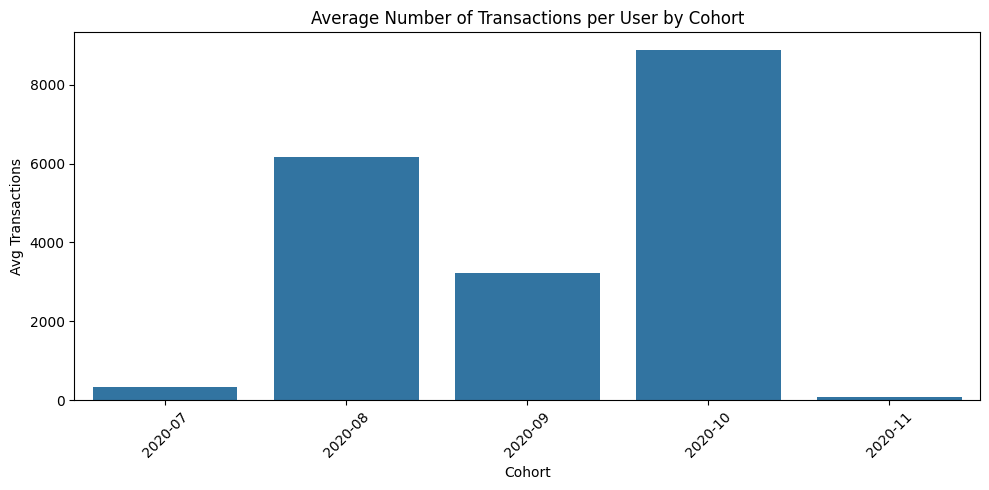

In [349]:
plt.figure(figsize=(10, 5))
sns.barplot(data=frequency, x="cohort", y="num_transactions")
plt.title("Average Number of Transactions per User by Cohort")
plt.ylabel("Avg Transactions")
plt.xlabel("Cohort")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
#plotting the values

In [350]:
final_df['incidents'] = (final_df['type'] == 'incident').astype(int)
incident_rate = final_df.groupby('cohort')['incidents'].mean().reset_index(name = "Incidents_mean_cohorts")
incident_rate

,cohort,Incidents_mean_cohorts
0,2020-07,0.204893
1,2020-08,0.122403
2,2020-09,0.080980
3,2020-10,0.027006
4,2020-11,0.000000


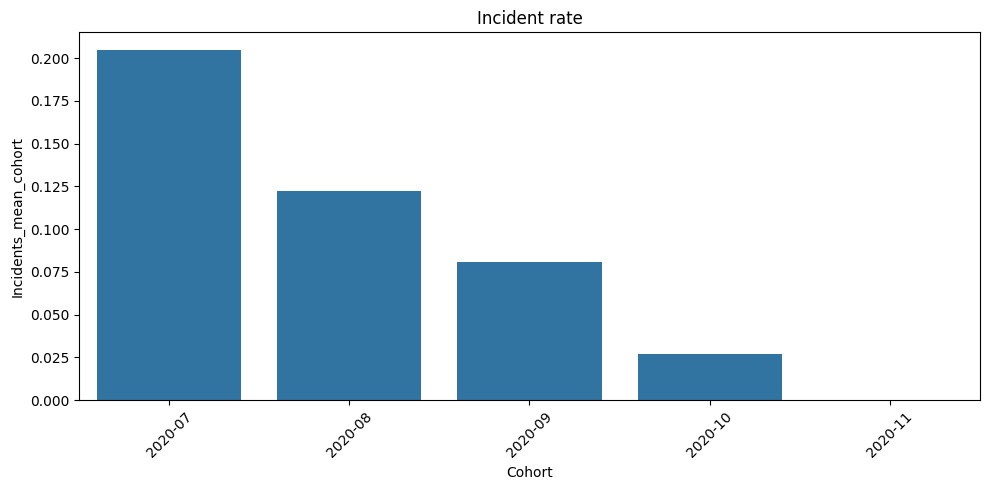

In [351]:
plt.figure(figsize=(10, 5))
sns.barplot(data=incident_rate, x="cohort", y="Incidents_mean_cohorts")
plt.title("Incident rate")
plt.ylabel("Incidents_mean_cohort")
plt.xlabel("Cohort")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [352]:
sum_total_amount_by_cohort = final_df.groupby("cohort")["total_amount"].sum().reset_index(name="sum_revenue_cohort")

In [353]:
sum_total_amount_by_cohort

,cohort,sum_revenue_cohort
0,2020-07,1635.0
1,2020-08,30800.0
2,2020-09,16115.0
3,2020-10,44435.0
4,2020-11,395.0


In [354]:
SUM_total_amount_complete = clean_fees_df["total_amount"].sum()
SUM_total_amount_complete

100755.0

In [355]:
sum_total_amount_by_cohort["sum_revenue_cohort"].sum()

93380.0

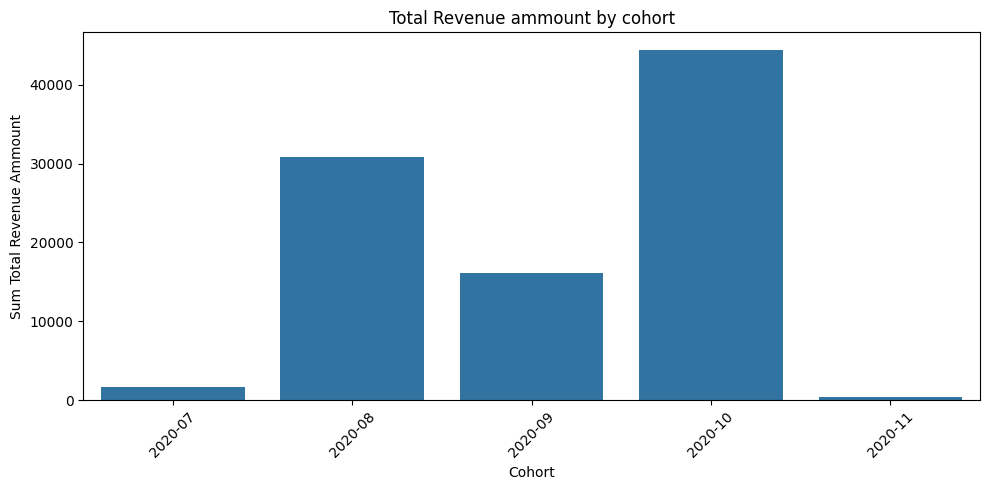

In [356]:
plt.figure(figsize=(10, 5))
sns.barplot(data=sum_total_amount_by_cohort, x="cohort", y="sum_revenue_cohort")
plt.title("Total Revenue ammount by cohort")
plt.ylabel("Sum Total Revenue Ammount")
plt.xlabel("Cohort")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()